In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import permutation_importance

# Загружаем датасет (например, данные по оттоку из первой практики)
df = pd.read_csv('../data/raw/Churn.csv')

# Быстрая предобработка (кодирование категориальных признаков, обработка пропусков TotalCharges)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# Выделим числовые и категориальные признаки
X = df.drop(columns=['customerID', 'Churn'])
X = pd.get_dummies(X, drop_first=True)
y = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

# Единое разбиение на train/test для честного сравнения дерева и леса
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Размер обучающей выборки: (5634, 30)
Размер тестовой выборки: (1409, 30)


C:\Users\User\AppData\Local\Temp\ipykernel_36756\4093348434.py:17: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


## 🌳 Сравнение одиночного дерева решений и случайного леса
Обучим классификаторы на одинаковых тренировочных данных и сравним их качество на тесте. Для случайного леса выберем $n\_estimators = 100$ (достаточное число деревьев для стабилизации ансамбля без избыточного роста времени обучения).

In [9]:
# 1. Одиночное дерево решений
dt_model = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

# 2. Случайный лес
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("--- Одиночное дерево решений ---")
print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}")
print(classification_report(y_test, dt_pred))

print("\n--- Случайный лес (Random Forest) ---")
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}")
print(classification_report(y_test, rf_pred))

--- Одиночное дерево решений ---
Accuracy: 0.7942
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.63      0.55      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409


--- Случайный лес (Random Forest) ---
Accuracy: 0.7878
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



## 📊 Встроенная важность признаков (Impurity-based Feature Importance)
Оценим важность признаков на основе среднего уменьшения примеси (Gini impurity) в случайном лесе.

C:\Users\User\AppData\Local\Temp\ipykernel_36756\1275041797.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_imp_df, x='Importance', y='Feature', palette='viridis')


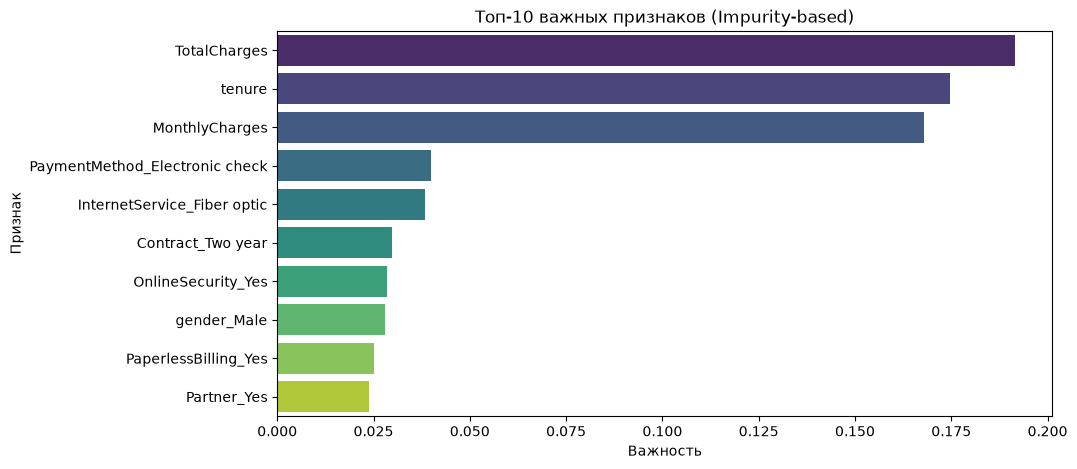

In [10]:
importances = rf_model.feature_importances_
feature_names = X.columns
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=feature_imp_df, x='Importance', y='Feature', palette='viridis')
plt.title('Топ-10 важных признаков (Impurity-based)')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.show()

## 🔄 Permutation Importance
Вычислим важность методом перестановки (Permutation Importance), который измеряет падение качества модели при случайном перемешивании значений конкретного признака. Это позволяет нивелировать склонность деревьев завышать важность признаков с большим числом уникальных значений.

C:\Users\User\AppData\Local\Temp\ipykernel_36756\96996141.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=perm_imp_df, x='Importance_Mean', y='Feature', palette='magma')


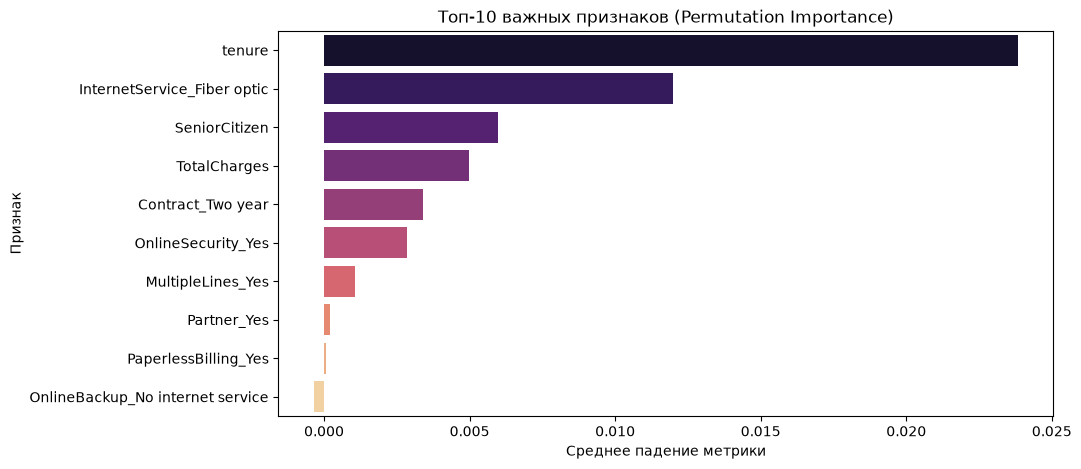

In [11]:
result = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)

perm_sorted_idx = result.importances_mean.argsort()[::-1]

perm_imp_df = pd.DataFrame({
    'Feature': X.columns[perm_sorted_idx],
    'Importance_Mean': result.importances_mean[perm_sorted_idx]
}).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=perm_imp_df, x='Importance_Mean', y='Feature', palette='magma')
plt.title('Топ-10 важных признаков (Permutation Importance)')
plt.xlabel('Среднее падение метрики')
plt.ylabel('Признак')
plt.show()

## 🔬 Интерпретация модели с помощью SHAP
Применим библиотеку SHAP для объяснения вклада каждого признака в предсказание для отдельных объектов.

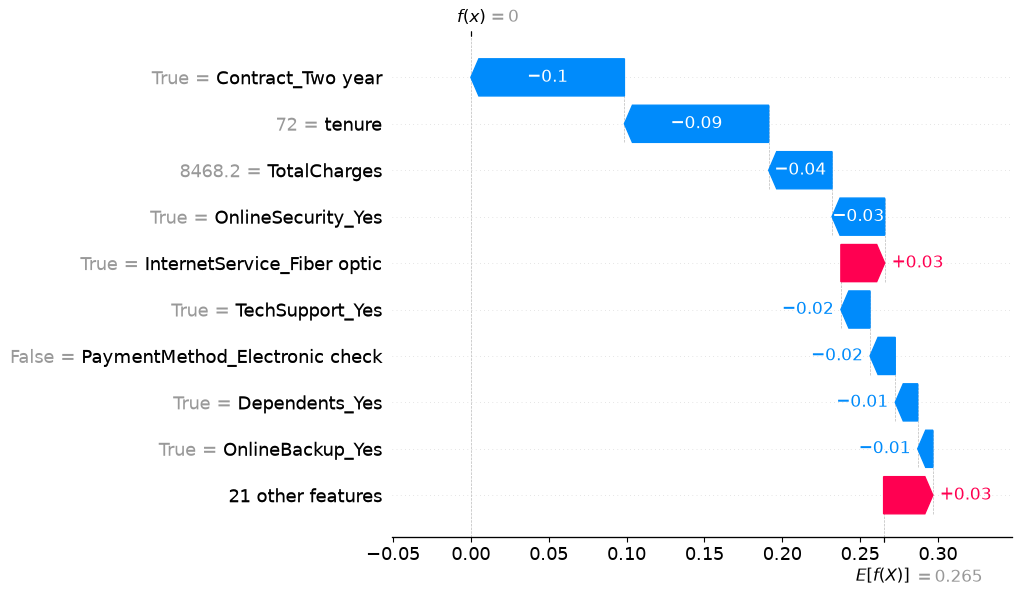

In [12]:
import shap

# Используем TreeExplainer для случайного леса
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test.iloc[:100])

# Передаем индекс объекта и индекс класса [0] (например, для класса 0 или 1)
shap.plots.waterfall(shap_values[0, :, 1])

## 📝 Выводы
1. **Сравнение моделей:** Случайный лес показал более высокую стабильность и точность по сравнению с одиночным деревом за счет усреднения предсказаний ансамбля решающих деревьев.
2. **Встроенная важность vs Permutation Importance:** Встроенная важность (`feature_importances_`) может завышать значимость непрерывных признаков или категориальных переменных с большим числом уникальных значений, так как у них больше возможностей для разбиения узлов. `Permutation Importance` оценивает реальное влияние на тестовых данных и выглядит более объективно.
3. **Роль SHAP:** В отличие от глобальной важности признаков, SHAP позволяет объяснить локальные предсказания — показать, какие именно факторы подтолкнули модель принять решение по конкретному клиенту.